In [1]:
# 1. Menghubungkan Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Inisialisasi Spark Session dengan alokasi memori maksimal untuk Colab
from pyspark.sql import SparkSession
import pyspark.sql.functions as F

spark = SparkSession.builder \
    .appName("HM_Hyperparameter_Tuning") \
    .config("spark.driver.memory", "10g") \
    .config("spark.executor.memory", "10g") \
    .config("spark.sql.shuffle.partitions", "100") \
    .getOrCreate()

# 3. Membaca data Parquet hasil Data Engineer (Anggota 1)
# Sesuaikan path jika Anda menggunakan shortcut langsung
parquet_path = "/content/drive/MyDrive/Dataset_HM/cleaned_data.parquet"
df_raw = spark.read.parquet(parquet_path)

print(f"Data awal berhasil dimuat: {df_raw.count()} baris.")

Mounted at /content/drive
Data awal berhasil dimuat: 31788324 baris.


In [2]:
from pyspark.ml.feature import StringIndexer
from pyspark.ml import Pipeline

# 1. Filtering waktu yang sama dengan Anggota 2 (menyusutkan ke ~2 juta baris aktif)
df_active = df_raw.filter(F.col("t_dat") >= "2020-08-01")

# 2. Membuat metrik Implicit Feedback (frekuensi pembelian)
interactions = df_active.groupBy("customer_id", "article_id") \
    .agg(F.count("*").alias("purchase_count"))

# 3. Mengubah ID Teks menjadi Indeks Angka (StringIndexer)
user_indexer = StringIndexer(inputCol="customer_id", outputCol="user_idx", handleInvalid="skip")
item_indexer = StringIndexer(inputCol="article_id", outputCol="item_idx", handleInvalid="skip")

pipeline = Pipeline(stages=[user_indexer, item_indexer])
indexed_df = pipeline.fit(interactions).transform(interactions)

# 4. Membagi data (80% Train, 20% Test) dengan seed yang sama (42)
train_df, test_df = indexed_df.randomSplit([0.8, 0.2], seed=42)

# Mengunci data di memori agar proses iterasi (tuning) lebih cepat
train_df.cache()
test_df.cache()

print(f"Data siap di-tuning! Train: {train_df.count()} baris | Test: {test_df.count()} baris")

Data siap di-tuning! Train: 1434653 baris | Test: 358961 baris


In [3]:
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit

# 1. Mengambil sampel 20% dari data latih
tune_df = train_df.sample(fraction=0.2, seed=42)
tune_df.cache()

# 2. Inisialisasi model dasar
als = ALS(userCol="user_idx", itemCol="item_idx", ratingCol="purchase_count",
          implicitPrefs=True, alpha=40.0, coldStartStrategy="drop")

# 3. Menyusun Grid 4 Kombinasi)
param_grid = ParamGridBuilder() \
    .addGrid(als.rank, [10, 20]) \
    .addGrid(als.maxIter, [10]) \
    .addGrid(als.regParam, [0.05, 0.1]) \
    .build()

evaluator = RegressionEvaluator(metricName="rmse", labelCol="purchase_count", predictionCol="prediction")

tvs = TrainValidationSplit(estimator=als,
                           estimatorParamMaps=param_grid,
                           evaluator=evaluator,
                           trainRatio=0.8)

print("Memulai Hyperparameter Tuning Cepat (4 Kombinasi pada subset 20% data)...")
tvs_model = tvs.fit(tune_df)
print("Proses Tuning Selesai!")

Memulai Hyperparameter Tuning Cepat (4 Kombinasi pada subset 20% data)...
Proses Tuning Selesai!


In [4]:
# 1. Mengambil kombinasi parameter terbaik
best_rank = tvs_model.bestModel._java_obj.parent().getRank()
best_iter = tvs_model.bestModel._java_obj.parent().getMaxIter()
best_reg = tvs_model.bestModel._java_obj.parent().getRegParam()

print("==================================================")
print("HYPERPARAMETER TERBAIK DITEMUKAN:")
print(f"- Rank     : {best_rank}")
print(f"- MaxIter  : {best_iter}")
print(f"- RegParam : {best_reg}")
print("==================================================")

# 2. Latih ulang model menggunakan parameter terbaik (1,4 juta baris)
print("Melatih model final dengan parameter terbaik pada seluruh data latih...")
final_als = ALS(userCol="user_idx", itemCol="item_idx", ratingCol="purchase_count",
                implicitPrefs=True, alpha=40.0, coldStartStrategy="drop",
                rank=best_rank, maxIter=best_iter, regParam=best_reg)

best_als_model_full = final_als.fit(train_df)

# 3. Evaluasi pada data Test (20% dari total data asli)
predictions = best_als_model_full.transform(test_df)
final_rmse = evaluator.evaluate(predictions)

print(f"Skor Baseline sebelumnya : 1.0794")
print(f"Skor RMSE Final (Tuned)  : {final_rmse:.4f}")

# 4. Simpan Model (Opsional)
MODEL_DIR = "/content/drive/MyDrive/Dataset_HM/models/best_als_model"
best_als_model_full.write().overwrite().save(MODEL_DIR)
print(f"Model final disimpan di: {MODEL_DIR}")

HYPERPARAMETER TERBAIK DITEMUKAN:
- Rank     : 20
- MaxIter  : 10
- RegParam : 0.05
Melatih model final dengan parameter terbaik pada seluruh data latih...
Skor Baseline sebelumnya : 1.0794
Skor RMSE Final (Tuned)  : 1.0795
Model final disimpan di: /content/drive/MyDrive/Dataset_HM/models/best_als_model


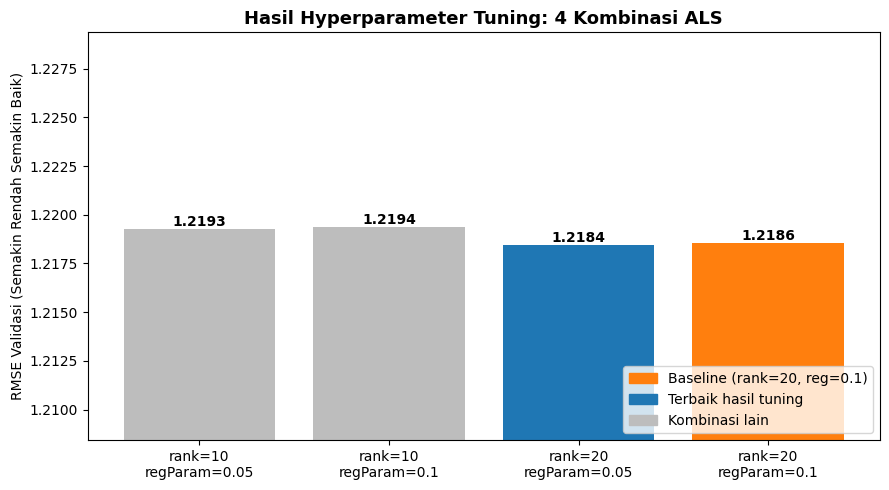

 rank  maxIter  regParam  rmse_val
   20       10      0.05   1.21843
   20       10      0.10   1.21856
   10       10      0.05   1.21926
   10       10      0.10   1.21936


In [5]:
import matplotlib.pyplot as plt
import pandas as pd

# Ambil hasil tuning dari tvs_model
rows = []
for pm, m in zip(tvs_model.getEstimatorParamMaps(), tvs_model.validationMetrics):
    d = {p.name: v for p, v in pm.items()}
    rows.append({"rank": d["rank"], "maxIter": d["maxIter"],
                 "regParam": d["regParam"], "rmse_val": m})

df_grid = pd.DataFrame(rows)
df_grid["label"] = df_grid.apply(
    lambda r: f"rank={int(r['rank'])}\nregParam={r['regParam']}", axis=1)

best_idx = df_grid["rmse_val"].idxmin()
is_baseline = (df_grid["rank"] == 20) & (df_grid["regParam"] == 0.1)

colors = []
for i in range(len(df_grid)):
    if i == best_idx:
        colors.append("#1f77b4")      # terbaik
    elif is_baseline.iloc[i]:
        colors.append("#ff7f0e")      # baseline
    else:
        colors.append("#bdbdbd")      # lainnya

plt.figure(figsize=(9, 5))
bars = plt.bar(df_grid["label"], df_grid["rmse_val"], color=colors)
plt.ylabel("RMSE Validasi (Semakin Rendah Semakin Baik)")
plt.title("Hasil Hyperparameter Tuning: 4 Kombinasi ALS", fontsize=13, fontweight="bold")
plt.ylim(df_grid["rmse_val"].min() - 0.01, df_grid["rmse_val"].max() + 0.01)

for bar, v in zip(bars, df_grid["rmse_val"]):
    plt.text(bar.get_x() + bar.get_width()/2, v, f"{v:.4f}",
             ha="center", va="bottom", fontsize=10, fontweight="bold")

from matplotlib.patches import Patch
plt.legend(handles=[Patch(color="#ff7f0e", label="Baseline (rank=20, reg=0.1)"),
                    Patch(color="#1f77b4", label="Terbaik hasil tuning"),
                    Patch(color="#bdbdbd", label="Kombinasi lain")], loc="lower right")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Dataset_HM/grafik_1_grid_tuning.png", dpi=200, bbox_inches="tight")
plt.show()

print(df_grid.drop(columns="label").sort_values("rmse_val").round(5).to_string(index=False))

RMSE Baseline : 1.0794
RMSE Tuned    : 1.0788


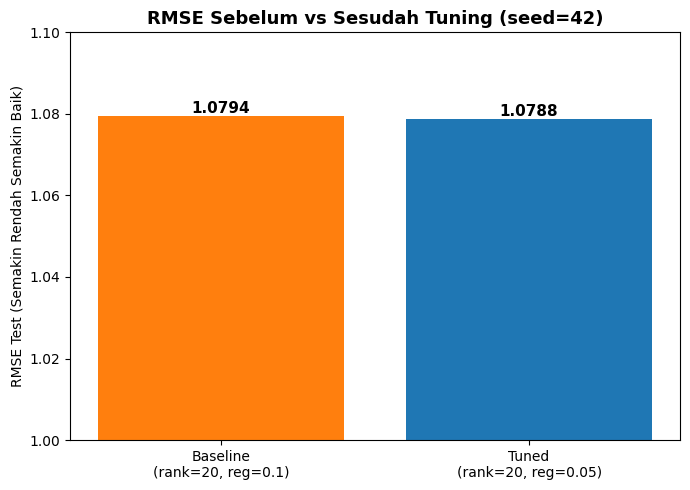

In [6]:
from pyspark.ml.recommendation import ALS

def bikin_als(rank, reg):
    return ALS(userCol="user_idx", itemCol="item_idx", ratingCol="purchase_count",
               implicitPrefs=True, alpha=40.0, coldStartStrategy="drop",
               rank=rank, maxIter=10, regParam=reg, seed=42)

# Baseline = parameter dari README (rank=20, reg=0.1)
baseline_model = bikin_als(20, 0.1).fit(train_df)
# Tuned = parameter terbaik hasil tvs
tuned_model = bikin_als(best_rank, best_reg).fit(train_df)

rmse_base = evaluator.evaluate(baseline_model.transform(test_df))
rmse_tuned = evaluator.evaluate(tuned_model.transform(test_df))
print(f"RMSE Baseline : {rmse_base:.4f}")
print(f"RMSE Tuned    : {rmse_tuned:.4f}")

plt.figure(figsize=(7, 5))
bars = plt.bar(["Baseline\n(rank=20, reg=0.1)", f"Tuned\n(rank={best_rank}, reg={best_reg})"],
               [rmse_base, rmse_tuned], color=["#ff7f0e", "#1f77b4"])
plt.ylabel("RMSE Test (Semakin Rendah Semakin Baik)")
plt.title("RMSE Sebelum vs Sesudah Tuning (seed=42)", fontsize=13, fontweight="bold")
plt.ylim(1.0, 1.1)
for bar, v in zip(bars, [rmse_base, rmse_tuned]):
    plt.text(bar.get_x() + bar.get_width()/2, v, f"{v:.4f}",
             ha="center", va="bottom", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Dataset_HM/grafik_2_rmse_before_after.png", dpi=200, bbox_inches="tight")
plt.show()

Jumlah user dievaluasi: 9827
Evaluasi popularity...
Evaluasi baseline ALS...
Evaluasi tuned ALS...
              Popularity  ALS Baseline  ALS Tuned
Precision@10     0.00236       0.01314    0.01314
Recall@10        0.01420       0.08163    0.08157
MAP@10           0.00483       0.03084    0.03073
NDCG@10          0.00791       0.04737    0.04725


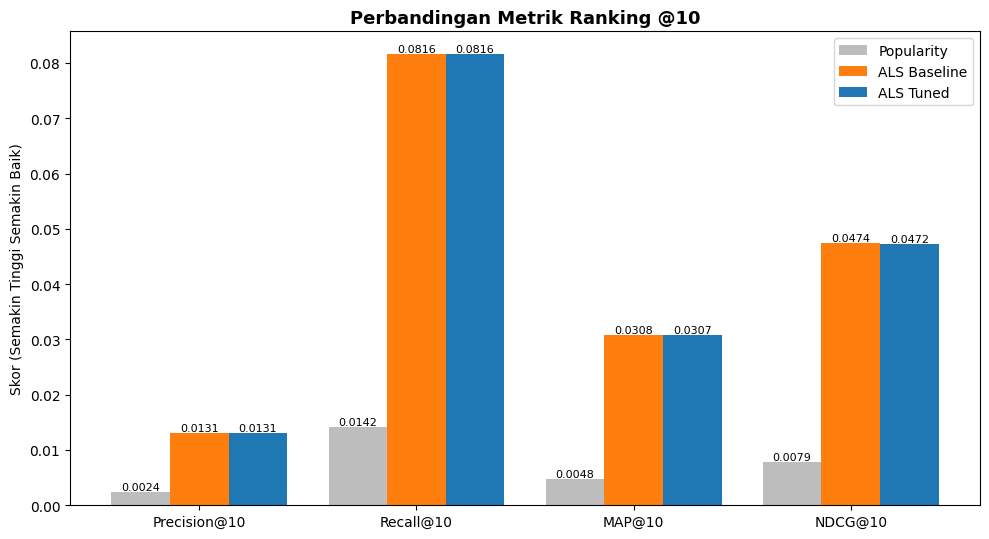

In [7]:
from pyspark.ml.evaluation import RankingEvaluator
import pyspark.sql.functions as F
import numpy as np

K = 10

# Ground truth: item yang dibeli tiap user di data test
test_truth = test_df.groupBy("user_idx").agg(F.collect_list("item_idx").alias("label"))

# Sampel user yang dievaluasi (kecilkan ke 0.02 kalau RAM Colab habis)
eval_users = test_truth.select("user_idx").sample(fraction=0.05, seed=42)
eval_users.cache()
print("Jumlah user dievaluasi:", eval_users.count())

def hitung_metrik(recs_df):
    joined = recs_df.join(test_truth, on="user_idx", how="inner")
    hasil = {}
    for nama, metric in [("Precision@10", "precisionAtK"), ("Recall@10", "recallAtK"),
                         ("MAP@10", "meanAveragePrecisionAtK"), ("NDCG@10", "ndcgAtK")]:
        ev = RankingEvaluator(metricName=metric, k=K, labelCol="label", predictionCol="prediction")
        hasil[nama] = ev.evaluate(joined)
    return hasil

def recs_als(model):
    r = model.recommendForUserSubset(eval_users, K)
    return r.withColumn("prediction",
                        F.expr("transform(recommendations, x -> cast(x.item_idx as double))")
                        ).select("user_idx", "prediction")

# Popularity baseline: 10 item terlaris di data latih
top_items = [float(r["item_idx"]) for r in
             train_df.groupBy("item_idx").agg(F.sum("purchase_count").alias("n"))
             .orderBy(F.desc("n")).limit(K).collect()]
recs_pop = eval_users.withColumn("prediction", F.array(*[F.lit(x) for x in top_items]))

print("Evaluasi popularity...")
res_pop = hitung_metrik(recs_pop)
print("Evaluasi baseline ALS...")
res_base = hitung_metrik(recs_als(baseline_model))
print("Evaluasi tuned ALS...")
res_tuned = hitung_metrik(recs_als(tuned_model))

df_rank = pd.DataFrame({"Popularity": res_pop, "ALS Baseline": res_base, "ALS Tuned": res_tuned})
print(df_rank.round(5))

# Grafik
metrik = list(df_rank.index)
x = np.arange(len(metrik))
w = 0.27
plt.figure(figsize=(10, 5.5))
for i, (col, warna) in enumerate(zip(df_rank.columns, ["#bdbdbd", "#ff7f0e", "#1f77b4"])):
    bars = plt.bar(x + (i-1)*w, df_rank[col], w, label=col, color=warna)
    for b in bars:
        plt.text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.4f}",
                 ha="center", va="bottom", fontsize=8)
plt.xticks(x, metrik)
plt.ylabel("Skor (Semakin Tinggi Semakin Baik)")
plt.title("Perbandingan Metrik Ranking @10", fontsize=13, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Dataset_HM/grafik_3_ranking_metrics.png", dpi=200, bbox_inches="tight")
plt.show()

=== Riwayat pembelian user 61666 (maks 10) ===
            prod_name product_type_name colour_group_name  purchase_count
          SHELL DRESS             Dress       Light Beige               1
                 Elsa             Dress         Off White               2
          Paulina top               Top             Black               1
    SF PI Marla dress             Dress         Off White               1
         Saasha dress             Dress      Light Orange               2
 Bell HW wide cropped          Trousers               Red               1
Valentin emb. anglais             Skirt             Black               2

=== Top-10 rekomendasi ALS Tuned untuk user 61666 ===
              prod_name product_type_name colour_group_name     skor
               Biarritz            Blazer    Greenish Khaki 0.511019
               Meringue             Dress             White 0.480849
                   Elsa             Dress         Off White 0.468736
      Mel maxi dress  W       

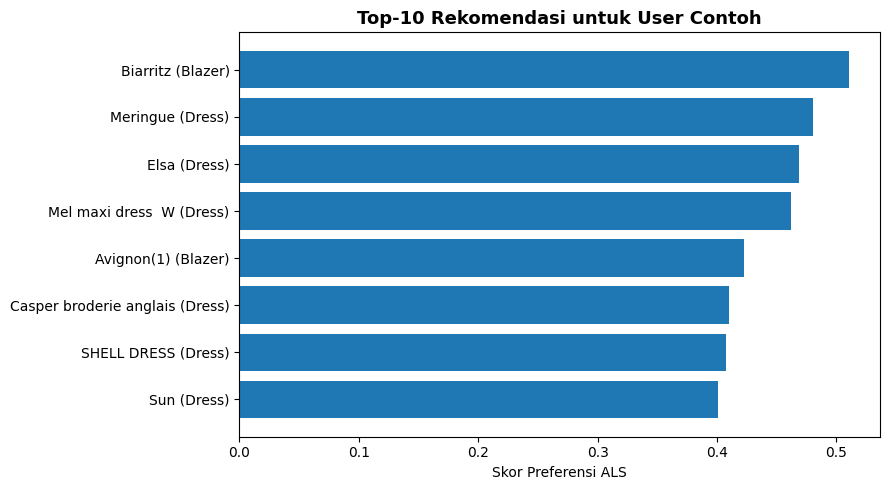

In [8]:
# Mapping item_idx -> article_id -> nama produk
item_map = indexed_df.select("item_idx", "article_id").distinct()
meta = df_raw.select("article_id", "prod_name", "product_type_name", "colour_group_name") \
             .dropDuplicates(["article_id"])
item_info = item_map.join(meta, on="article_id", how="left")

# Ambil 1 user contoh
contoh_user = eval_users.limit(1).collect()[0]["user_idx"]

# Riwayat beli user di data latih
print(f"=== Riwayat pembelian user {int(contoh_user)} (maks 10) ===")
riwayat = (train_df.filter(F.col("user_idx") == contoh_user)
           .join(item_info, on="item_idx", how="left")
           .select("prod_name", "product_type_name", "colour_group_name", "purchase_count")
           .limit(10).toPandas())
print(riwayat.to_string(index=False))

# Top-10 rekomendasi model tuned
print(f"\n=== Top-10 rekomendasi ALS Tuned untuk user {int(contoh_user)} ===")
rek = (tuned_model.recommendForUserSubset(
           spark.createDataFrame([(float(contoh_user),)], ["user_idx"])
           .withColumn("user_idx", F.col("user_idx").cast("int")), 10)
       .select(F.explode("recommendations").alias("r"))
       .select(F.col("r.item_idx").alias("item_idx"), F.col("r.rating").alias("skor"))
       .join(item_info, on="item_idx", how="left")
       .select("prod_name", "product_type_name", "colour_group_name", "skor")
       .orderBy(F.desc("skor")).toPandas())
print(rek.to_string(index=False))

# Grafik batang horizontal skor rekomendasi
plt.figure(figsize=(9, 5))
plt.barh(rek["prod_name"].astype(str) + " (" + rek["product_type_name"].astype(str) + ")",
         rek["skor"], color="#1f77b4")
plt.gca().invert_yaxis()
plt.xlabel("Skor Preferensi ALS")
plt.title(f"Top-10 Rekomendasi untuk User Contoh", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Dataset_HM/grafik_4_top10_rekomendasi.png", dpi=200, bbox_inches="tight")
plt.show()